# 01 — Probability

**Learning goals:** use counting rules, calculate conditional probabilities, and verify results by enumeration or simulation.

For each problem, distinguish the mathematical model from the computation. The code checks the result; the explanation should make clear why the method is appropriate.

## Problem 1: Exactly two heads in three fair coin tosses

**Question.** What is the probability of obtaining exactly two heads in three independent tosses of a fair coin?

**Assumptions.** Each toss has probability \(1/2\) of heads, and tosses are independent.

**Mathematical reasoning.** There are \(2^3=8\) equally likely sequences. Choose which two of the three positions contain heads: \(inom{3}{2}=3\). Therefore,

\[
P(X=2)=\binom{3}{2}\left(\frac12\right)^2\left(\frac12\right)=\frac38=0.375.
\]

In [2]:
from itertools import product
from math import comb

n_tosses = 3
target_heads = 2

theoretical_probability = comb(n_tosses, target_heads) / (2 ** n_tosses)
outcomes = list(product(("H", "T"), repeat=n_tosses))
favourable = [outcome for outcome in outcomes if outcome.count("H") == target_heads]
enumerated_probability = len(favourable) / len(outcomes)

print(f"Theoretical probability: {theoretical_probability:.3f}")
print(f"Enumerated probability:  {enumerated_probability:.3f}")
print("Favourable outcomes:", ["".join(x) for x in favourable])

assert theoretical_probability == enumerated_probability

Theoretical probability: 0.375
Enumerated probability:  0.375
Favourable outcomes: ['HHT', 'HTH', 'THH']


**Verification.** The binomial formula and explicit enumeration agree.

**Interpretation.** Three of the eight equally likely outcomes contain exactly two heads, so the probability is 37.5%.

**Common mistake.** Counting only one arrangement (for example, HHT) and forgetting HT H and THH.

## Problem 2: Conditional probability without replacement

**Question.** A bag contains 3 red and 2 blue balls. Two balls are drawn without replacement. Given that the first ball is red, what is the probability that the second is red?

**Mathematical reasoning.** Once a red ball has been drawn, 2 red balls remain among 4 balls. Hence,

\[
P(R_2\mid R_1)=\frac{P(R_1\cap R_2)}{P(R_1)}
=\frac{(3/5)(2/4)}{3/5}=\frac12.
\]

In [3]:
from fractions import Fraction

p_first_red = Fraction(3, 5)
p_second_red_given_first_red = Fraction(2, 4)
joint_probability = p_first_red * p_second_red_given_first_red
conditional_probability = joint_probability / p_first_red

print("Joint probability P(R1 and R2):", joint_probability)
print("Conditional probability P(R2 | R1):", conditional_probability)
assert conditional_probability == Fraction(1, 2)

Joint probability P(R1 and R2): 3/10
Conditional probability P(R2 | R1): 1/2


**Verification.** The conditional probability simplifies to \(1/2\).

**Interpretation.** The draws are dependent because the first draw changes the contents of the bag.

## Problem 3: Bayes' theorem

A condition affects 1% of a population. A test has 90% sensitivity and a 5% false-positive rate. If a person tests positive, what is the probability they have the condition?

Let \(D\) mean the condition is present and \(+\) mean the test is positive.

\[
P(D\mid +)=\frac{P(+\mid D)P(D)}
{P(+\mid D)P(D)+P(+\mid \neg D)P(\neg D)}.
\]

The values below are illustrative assumptions, not claims about any real test.

In [4]:
from fractions import Fraction

p_condition = Fraction(1, 100)
sensitivity = Fraction(9, 10)
false_positive_rate = Fraction(5, 100)

p_positive = sensitivity * p_condition + false_positive_rate * (1 - p_condition)
p_condition_given_positive = sensitivity * p_condition / p_positive

print(f"P(condition | positive) = {float(p_condition_given_positive):.3%}")
print(f"Exact fraction = {p_condition_given_positive}")
assert 0 < float(p_condition_given_positive) < 1

P(condition | positive) = 15.385%
Exact fraction = 2/13


**Interpretation.** Despite 90% sensitivity, the posterior probability is only about 15.4% under these assumptions. The low base rate and false positives matter.

**Lesson.** A test's sensitivity alone does not determine the probability that a positive result is correct.

## Reflection

- Which assumptions made the outcomes equally likely in Problem 1?
- How would replacement change Problem 2?
- How would the Bayes result change if the base rate increased?

## Problem 4: Sum of 8 in two fair die rolls

**Question.** A fair six-sided die is rolled twice. What is the probability that the sum of the two rolls is 8?

**Assumptions.** Each roll is uniform on \(\{1,2,3,4,5,6\}\), and the two rolls are independent.

**Enumeration.** There are \(6^2=36\) equally likely ordered pairs \((a,b)\). The pairs with \(a+b=8\) are

\[
(2,6),\ (3,5),\ (4,4),\ (5,3),\ (6,2),
\]

which is 5 outcomes, so the probability is \(5/36\).

**Mathematical reasoning.** Let \(X_1\) and \(X_2\) be the two rolls. If \(X_1=a\), then \(X_2\) must equal \(8-a\), and this is a valid face only when

\[
1 \le 8-a \le 6 \iff 2 \le a \le 7.
\]

Since \(a\le 6\), the first roll can be any of \(a\in\{2,3,4,5,6\}\), which gives 5 favorable pairs. Therefore,

\[
P(X_1+X_2=8)=\frac{5}{6^2}=\frac{5}{36}\approx 0.1389.
\]

In [9]:
#enumerating all possible outcomes
outcomes = [
    (die1, die2)
    for die1 in range(1, 7)
    for die2 in range(1, 7)
]

# outcomes whose sum is 8
favorable_outcomes = [
    outcome
    for outcome in outcomes
    if sum(outcome) == 8
]

# Calculating probability
probability = len(favorable_outcomes) / len(outcomes)

print("Total outcomes:", len(outcomes))
print("Favorable outcomes:", favorable_outcomes)
print("Number of favorable outcomes:", len(favorable_outcomes))
print("Probability:", probability)
print(f"Percentage: {probability:.2%}")

Total outcomes: 36
Favorable outcomes: [(2, 6), (3, 5), (4, 4), (5, 3), (6, 2)]
Number of favorable outcomes: 5
Probability: 0.1388888888888889
Percentage: 13.89%


**Verification.** The counting argument, explicit enumeration, and the exact-fraction Python check all agree: \(P(X_1+X_2=8)=\tfrac{5}{36}\).

**Interpretation.** Five of the 36 equally likely outcomes have a sum of 8, so the probability is about 13.9%, or roughly 1 roll pair in 7.

**Common mistake.** Counting unordered pairs \(\{2,6\}, \{3,5\}, \{4,4\}\) and getting 3 outcomes. This treats \((2,6)\) and \((6,2)\) as the same outcome, but unordered pairs are not equally likely: \(\{4,4\}\) can occur in only one way, while the others can each occur in two.

## Problem 5: Sum greater than 9 in two fair die rolls

**Question.** A fair six-sided die is rolled twice. What is the probability that the sum of the two rolls is greater than 9?

**Assumptions.** Each roll is uniform on \(\{1,2,3,4,5,6\}\), and the two rolls are independent.

**Enumeration.** There are \(6^2=36\) equally likely ordered pairs \((a,b)\). A sum greater than 9 means a sum of 10, 11, or 12:

\[
\underbrace{(4,6),\ (5,5),\ (6,4)}_{\text{sum }10},\quad
\underbrace{(5,6),\ (6,5)}_{\text{sum }11},\quad
\underbrace{(6,6)}_{\text{sum }12}.
\]

That is \(3+2+1=6\) favorable outcomes.

**Mathematical reasoning.** If the first roll is \(a\), the second roll \(b\) must satisfy \(b \ge 10-a\) with \(b\le 6\). Counting valid values of \(b\) for each \(a\): none for \(a\in\{1,2,3\}\), one for \(a=4\), two for \(a=5\), and three for \(a=6\). Therefore,

\[
P(X_1+X_2>9)=\frac{0+0+0+1+2+3}{6^2}=\frac{6}{36}=\frac16\approx 0.1667.
\]


In [10]:
from fractions import Fraction
from itertools import product

THRESHOLD = 9

outcomes = list(product(range(1, 7), repeat=2))
favorable = [(a, b) for a, b in outcomes if a + b > THRESHOLD]

p_enumeration = Fraction(len(favorable), len(outcomes))
p_math = Fraction(6, 36)

print(f"Total outcomes:     {len(outcomes)}")
print(f"Favorable outcomes: {len(favorable)}")
print(f"Favorable pairs:    {favorable}")
print(f"P (enumeration):    {len(favorable)}/{len(outcomes)} = {p_enumeration} = {float(p_enumeration):.4f}")
print(f"P (mathematical):   {p_math} = {float(p_math):.4f}")
print(f"Match:              {p_enumeration == p_math}")

assert p_enumeration == p_math

Total outcomes:     36
Favorable outcomes: 6
Favorable pairs:    [(4, 6), (5, 5), (5, 6), (6, 4), (6, 5), (6, 6)]
P (enumeration):    6/36 = 1/6 = 0.1667
P (mathematical):   1/6 = 0.1667
Match:              True


**Verification.** The counting argument, explicit enumeration, and the exact-fraction Python check all agree: \(P(X_1+X_2>9)=\tfrac{1}{6}\).

**Interpretation.** Six of the 36 equally likely outcomes have a sum greater than 9, so the probability is about 16.7%, or 1 roll pair in 6.

**Common mistake.** Counting \((5,6)\) and \((6,5)\) as one outcome, or forgetting \((5,5)\). Either slip gives a count other than 6. Another is using "greater than 9" as "at least 9", which wrongly includes the sum 9 and gives \(10/36\).


## Problem 6: Sum greater than 9, given the first roll is at least 4

**Question.** A fair six-sided die is rolled twice. Given that the first roll is 4 or greater, what is the probability that the sum of the two rolls is greater than 9?

**Assumptions.** Each roll is uniform on \(\{1,2,3,4,5,6\}\), and the two rolls are independent. Let \(A\) be the event "the sum is greater than 9" and \(B\) the event "the first roll is at least 4".

**Conditionally possible outcomes.** Given \(B\), the first roll is \(a\in\{4,5,6\}\) and the second roll \(b\) is unrestricted, so \(|B|=3\cdot 6=18\) ordered pairs:

\[
(4,1),\dots,(4,6),\quad (5,1),\dots,(5,6),\quad (6,1),\dots,(6,6).
\]

**Favorable outcomes satisfying both conditions.** From these 18 pairs, keep those with \(a+b>9\):

\[
(4,6),\ (5,5),\ (5,6),\ (6,4),\ (6,5),\ (6,6).
\]

So \(|A\cap B|=6\).

**Mathematical reasoning.** Using the conditional probability formula,

\[
P(A\mid B)=\frac{P(A\cap B)}{P(B)},
\qquad
P(B)=\frac{18}{36}=\frac12,
\qquad
P(A\cap B)=\frac{6}{36}=\frac16.
\]

Therefore,

\[
P(A\mid B)=\frac{1/6}{1/2}=\frac13\approx 0.3333.
\]

In [11]:
from fractions import Fraction
from itertools import product

outcomes = list(product(range(1, 7), repeat=2))

B = [(a, b) for a, b in outcomes if a >= 4]
A_and_B = [(a, b) for a, b in B if a + b > 9]

p_B = Fraction(len(B), len(outcomes))
p_A_and_B = Fraction(len(A_and_B), len(outcomes))

p_formula = p_A_and_B / p_B                      # P(A and B) / P(B)
p_reduced = Fraction(len(A_and_B), len(B))       # count inside the reduced sample space
p_math = Fraction(1, 3)

print(f"|B| = {len(B)}  ->  P(B) = {p_B}")
print(f"|A and B| = {len(A_and_B)}  ->  P(A and B) = {p_A_and_B}")
print(f"A and B outcomes: {A_and_B}")
print(f"P(A|B) by formula:       {p_formula}")
print(f"P(A|B) by reduced space: {p_reduced}")
print(f"P(A|B) by hand:          {p_math}")

assert p_formula == p_reduced == p_math

|B| = 18  ->  P(B) = 1/2
|A and B| = 6  ->  P(A and B) = 1/6
A and B outcomes: [(4, 6), (5, 5), (5, 6), (6, 4), (6, 5), (6, 6)]
P(A|B) by formula:       1/3
P(A|B) by reduced space: 1/3
P(A|B) by hand:          1/3


**Verification.** The conditional probability formula, direct counting inside the 18-outcome reduced sample space (\(6/18\)), and the exact-fraction Python check all agree: \(P(A\mid B)=\tfrac13\).

**Interpretation.** Knowing the first roll is at least 4 raises the chance of a sum above 9 from \(1/6\) to \(1/3\). Every outcome with sum greater than 9 already has a first roll of at least 4, so \(A\cap B = A\), and conditioning on \(B\) only shrinks the sample space from 36 outcomes to 18.

**Common mistake.** Dividing by 36 instead of 18, which gives \(6/36=1/6\) and ignores the condition. The denominator must be the size of the conditioned sample space, \(P(B)\), not the full one.

## Problem 7: Probability of disease given a positive diagnostic test

**Question.** A disease affects 1% of a population. A diagnostic test has sensitivity 95% (it is positive for 95% of people who have the disease) and specificity 90% (it is negative for 90% of people who do not have the disease). A randomly selected person tests positive. What is the probability that this person actually has the disease?

**Assumptions.** The person is chosen uniformly at random from the population, so \(P(D)\) equals the disease prevalence. The sensitivity and specificity apply to every person regardless of other characteristics.

**Events and given probabilities.** Let \(D\) be the event "the person has the disease" and \(+\) the event "the test is positive". Then

\[
P(D)=0.01,\qquad P(D^c)=0.99,
\]
\[
P(+\mid D)=0.95\ \text{(sensitivity)},\qquad
P(+\mid D^c)=1-0.90=0.10\ \text{(false-positive rate)}.
\]

The quantity to find is \(P(D\mid +)\), which is **not** the same as the sensitivity \(P(+\mid D)\).

**Mathematical reasoning.** First compute the total probability of a positive test using the law of total probability:

\[
P(+)=P(+\mid D)P(D)+P(+\mid D^c)P(D^c)=0.95(0.01)+0.10(0.99)=0.0095+0.099=0.1085.
\]

Then apply Bayes' theorem:

\[
P(D\mid +)=\frac{P(+\mid D)\,P(D)}{P(+)}=\frac{0.0095}{0.1085}=\frac{19}{217}\approx 0.0876.
\]

**Natural-frequency check.** Imagine 10,000 people. About 100 have the disease and 9,900 do not. Of the 100 with the disease, \(0.95\cdot 100=95\) test positive. Of the 9,900 without it, \(0.10\cdot 9900=990\) test positive. Among all \(95+990=1085\) positive tests, only 95 are true positives:

\[
\frac{95}{95+990}=\frac{95}{1085}=\frac{19}{217}.
\]

In [1]:
from fractions import Fraction

p_D = Fraction(1, 100)
p_pos_given_D = Fraction(95, 100)
p_pos_given_Dc = 1 - Fraction(90, 100)
p_Dc = 1 - p_D

p_pos = p_pos_given_D * p_D + p_pos_given_Dc * p_Dc
p_D_given_pos = p_pos_given_D * p_D / p_pos

print(f"P(+) = {p_pos} = {float(p_pos):.4f}")
print(f"P(D|+) = {p_D_given_pos} = {float(p_D_given_pos):.4f}")

# Natural-frequency check with 10,000 people
N = 10_000
sick = N * 1 // 100
healthy = N - sick
true_pos = sick * 95 // 100
false_pos = healthy * 10 // 100
print(f"true_pos={true_pos}, false_pos={false_pos}")

assert p_D_given_pos == Fraction(19, 217)
assert Fraction(true_pos, true_pos + false_pos) == p_D_given_pos

P(+) = 217/2000 = 0.1085
P(D|+) = 19/217 = 0.0876
true_pos=95, false_pos=990


**Verification.** Bayes' theorem, the natural-frequency count, and the exact-fraction Python check all agree: \(P(D\mid +)=\tfrac{19}{217}\approx 8.8\%\).

**Interpretation.** A positive result raises the chance of disease from 1% to about 8.8%, a roughly ninefold increase, but it is still far from 95%. The disease is rare, so the large healthy group produces many false positives (990) that swamp the small number of true positives (95). The sensitivity \(P(+\mid D)=0.95\) answers "if you are sick, how likely is a positive test?", while \(P(D\mid +)\) answers "if you tested positive, how likely are you sick?". These are different questions, and the second one also depends on how common the disease is.

**Common mistake.** Treating \(P(D\mid +)\) as if it equaled \(P(+\mid D)\) and concluding "a positive test means a 95% chance of disease". This confuses a conditional probability with its reverse and ignores the base rate \(P(D)=0.01\).

## Problem 8: Monte Carlo estimate of the probability that the sum exceeds 9

**Question.** Two fair six-sided dice are rolled. Estimate the probability that their sum is greater than 9 by simulation, and compare the estimate with the exact value \(1/6\) for 100, 1,000, 10,000, and 100,000 trials.

**Assumptions.** Each die is uniform on \(\{1,2,3,4,5,6\}\), the two dice are independent, and different trials are independent. The random number generator is seeded with a fixed value (`SEED = 42`) so the results can be reproduced.

**Mathematical reasoning.** Let \(I_k=1\) if the sum in trial \(k\) exceeds 9 and \(I_k=0\) otherwise. Each \(I_k\) is a Bernoulli random variable with \(p=\tfrac16\) (Problem 3). The Monte Carlo estimate from \(n\) trials is the sample proportion

\[
\hat p_n=\frac1n\sum_{k=1}^{n} I_k,
\qquad
E[\hat p_n]=p,
\qquad
\operatorname{SE}(\hat p_n)=\sqrt{\frac{p(1-p)}{n}}.
\]

So \(\hat p_n\) is unbiased, and its typical error shrinks like \(1/\sqrt n\): multiplying the number of trials by 100 reduces the standard error by a factor of 10.

In [10]:
import numpy as np

SEED = 42
THRESHOLD = 9
EXACT = 1 / 6

rng = np.random.default_rng(SEED)  # fixed seed -> reproducible results


def estimate(n_trials: int) -> float:
    """Roll two dice n_trials times; return the proportion with sum > THRESHOLD."""
    first = rng.integers(1, 7, size=n_trials)    # faces 1..6
    second = rng.integers(1, 7, size=n_trials)
    return np.mean(first + second > THRESHOLD)


print(f"Seed: {SEED}   Exact P(sum > {THRESHOLD}) = 1/6 = {EXACT:.6f}\n")
print(f"{'Trials':>10} {'Estimate':>10} {'Abs. error':>11} {'Std. error':>11}")
for n in (100, 1_000, 10_000, 100_000):
    p_hat = estimate(n)
    se = np.sqrt(EXACT * (1 - EXACT) / n)   # theoretical standard error
    print(f"{n:>10,} {p_hat:>10.4f} {abs(p_hat - EXACT):>11.4f} {se:>11.4f}")

Seed: 42   Exact P(sum > 9) = 1/6 = 0.166667

    Trials   Estimate  Abs. error  Std. error
       100     0.1700      0.0033      0.0373
     1,000     0.1690      0.0023      0.0118
    10,000     0.1656      0.0011      0.0037
   100,000     0.1673      0.0006      0.0012


Output with `SEED = 42` (the generator is created once, so run the whole script to reproduce these exact numbers):

| Trials | Estimate | Absolute error | Standard error |
|---:|---:|---:|---:|
| 100 | 0.1700 | 0.0033 | 0.0373 |
| 1,000 | 0.1690 | 0.0023 | 0.0118 |
| 10,000 | 0.1656 | 0.0011 | 0.0037 |
| 100,000 | 0.1673 | 0.0006 | 0.0012 |

**Verification.** The estimate from 100,000 trials, \(0.1673\), differs from the exact value \(1/6\approx 0.1667\) by only \(0.0006\), about half a standard error. Every estimate in the table lies within one standard error of \(1/6\), consistent with the theory.

**Interpretation.** The estimates move toward \(0.1667\) as the number of trials grows, but not necessarily in a perfectly steady way. In this run the absolute error happens to fall at every step, yet a different seed could give a larger error at 10,000 trials than at 1,000. The reliable pattern is the standard error, which shrinks like \(1/\sqrt n\). A simulated probability differs from the exact one because it is computed from a finite random sample: it is a random quantity with its own spread around \(p\), not a deterministic calculation.

**Common mistake.** Expecting the simulation to match \(1/6\) exactly, or treating a small error at one sample size as proof that the code is correct. Two coding slips are also common: using `np.random.randint(1, 6)`, whose upper bound is excluded so it only produces faces 1 to 5, and re-seeding inside the loop, which reuses the same random numbers and hides how the estimate varies.

## Convergence of the Monte Carlo Estimate

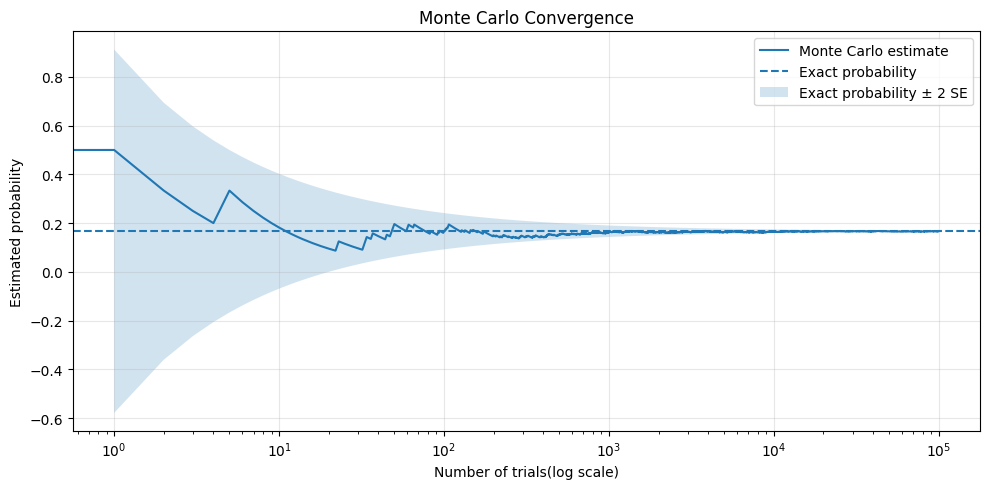

In [4]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n_trials = 100_000

first = rng.integers(1, 7, size=n_trials)
second = rng.integers(1, 7, size=n_trials)

success = (first + second > 9).astype(int)
cumulative_estimate = np.cumsum(success) / np.arange(1, n_trials + 1)

n=np.arange(1, n_trials+1)
exact=1/6
se=np.sqrt(exact*(1-exact)/n)

plt.figure(figsize=(10, 5))
plt.plot(cumulative_estimate, label="Monte Carlo estimate")
plt.axhline(1 / 6, linestyle="--", label="Exact probability")
plt.fill_between(
    n,
    exact - 2 * se,
    exact + 2 *se,
    alpha=0.2,
    label="Exact probability ± 2 SE"
)

plt.xscale("log")
plt.xlabel("Number of trials(log scale)")
plt.ylabel("Estimated probability")
plt.title("Monte Carlo Convergence")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

1. *Early fluctuation.* One new trial changes the estimate by
\[
\hat p_{n+1}-\hat p_n=\frac{I_{n+1}-\hat p_n}{n+1},
\]
a jump of size up to about \(1/n\). When \(n\) is small each trial carries a large share of the weight. For example \(\hat p_1\) must be 0 or 1. The standard error of the estimator is
\[
\operatorname{SE}(\hat p_n)=\sqrt{\frac{p(1-p)}{n}}=\sqrt{\frac{5}{36\,n}},
\]
about \(0.118\) at \(n=10\). It describes the sampling variability of \(\hat p_n\) across repeated experiments; it is not a bound on the error of one particular observed estimate.

2. *Stabilization.* By the strong law of large numbers, \(\hat p_n\to p\) almost surely. The mechanism is dilution, not compensation: later results do not "make up for" early ones, but each early result is divided by a growing \(n\). The spread shrinks like \(1/\sqrt n\).

3. *Exact equality.* \(\hat p_n=\tfrac16\) requires \(6S_n=n\), so \(n\) must be a multiple of 6 and exactly \(n/6\) successes must have occurred. It can therefore never hold at \(n=100{,}000\), which is not a multiple of 6. If it holds at \(n\) with \(S_n=n/6\), it cannot hold at \(n+1\): the next value is \(\tfrac{n/6}{n+1}\) or \(\tfrac{n/6+1}{n+1}\), and \(6S_{n+1}\) equals \(n\) or \(n+6\), never \(n+1\). So every exact hit lasts exactly one trial.

4. *Why the full curve.* It shows the path, not just its endpoints.Plotting the whole path reveals things four sample sizes cannot:

- It shows the \(1/\sqrt n\) scale of the fluctuations directly. The shaded band \(1/6\pm 2\,\text{SE}\) narrows as the curve settles. The band is a reference band built from the theoretical standard error and centered at the true value; it is not a confidence interval. Under a normal approximation (reasonable for large \(n\)), about 95% of individual estimates at one specified sample size fall inside it, but that is not a guarantee that the entire running curve stays inside. Staying inside for every \(n\ge 100\) in this run is an observation about one sample path, not a rule. Over an infinitely long path, the running estimate leaves any fixed-width band (in standard errors) infinitely often, by the law of the iterated logarithm.
- It shows that convergence is not monotone. The error can grow for a while (the curve drifts below \(1/6\) between roughly \(n=200\) and \(n=1{,}000\)) before shrinking again, which a short table can hide.
- Four separate runs would use independent samples, whereas the running estimates \(\hat p_n\) and \(\hat p_{n+1}\) share all but one of their observations, so neighboring points are strongly dependent. This does not make the curve smooth in the calculus sense: it is still a jagged path of discrete steps. What the shared data guarantees is that each step is small, \(\lvert\hat p_{n+1}-\hat p_n\rvert\le \tfrac1{n+1}\), so the curve can only change slowly. It is a single sample path, not many independent checks.
- A log-scaled \(n\)-axis keeps the large early swings visible next to the fine late behavior.